In [27]:
'''
Clustering
-> unsupervised learning
-> only feature no target
-> uses eigen value and eigen vector for PCA
-> uses elbow method 
    ->different from elbow in k neighbours
    ->highest drop point before any stable point
'''

'\nClustering\n-> unsupervised learning\n-> only feature no target\n-> uses eigen value and eigen vector for PCA\n-> uses elbow method \n    ->different from elbow in k neighbours\n    ->highest drop point before any stable point\n'

# K Means

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


# K Means Model
from sklearn.cluster import KMeans
# Data Preprocessing
from sklearn.preprocessing import StandardScaler, LabelEncoder
# Metrics
from sklearn.metrics import silhouette_score

In [29]:
df = pd.read_csv('D:\Data Science\Dataset\Mall_Customers.csv')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


### Checking Outliers

<Axes: >

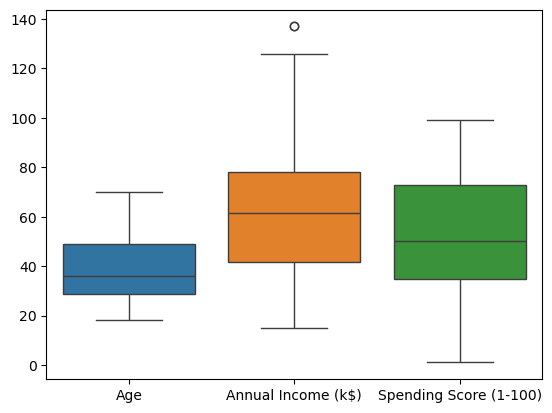

In [30]:
sns.boxplot(df[['Age','Annual Income (k$)','Spending Score (1-100)']])

In [31]:
le = LabelEncoder()

In [32]:
df['GenderID'] = le.fit_transform(df['Gender'])

In [33]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)', 'GenderID'],
      dtype='object')

## Features

In [34]:
features = [ 'Age', 'Annual Income (k$)','Spending Score (1-100)','GenderID']
X = df[features]

## Feature Scaling

In [35]:
scaler = StandardScaler()
X_scale = scaler.fit_transform(X)

## Elbow Method

In [36]:
import warnings
warnings.filterwarnings('ignore')

In [37]:
k_range = range(1,21)
error_rate =[]
for i in k_range:
    kmeans = KMeans(n_clusters=i)
    kmeans.fit_predict(X_scale)
    kmeans.inertia_
    error_rate.append(kmeans.inertia_)

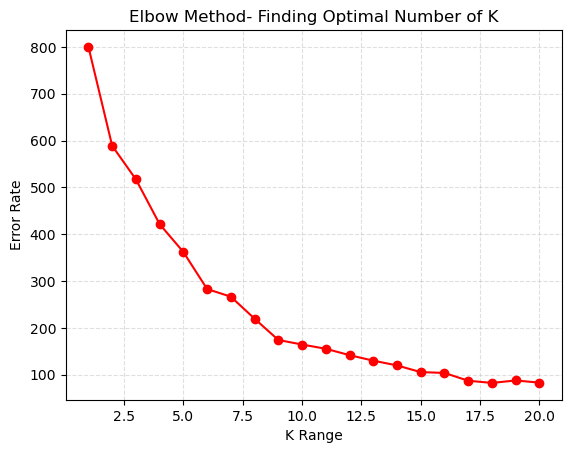

In [38]:
plt.plot(k_range, error_rate, marker = 'o', color = 'red')
plt.grid(linestyle = '--', alpha = 0.4)
plt.xlabel('K Range')
plt.ylabel('Error Rate')
plt.title('Elbow Method- Finding Optimal Number of K')
plt.show()

## Model Implementation

In [39]:
k = 5

model = KMeans(n_clusters=k)
clusters = model.fit_predict(X_scale)
clusters


array([3, 3, 1, 2, 2, 2, 1, 2, 0, 2, 0, 2, 1, 2, 0, 3, 1, 3, 0, 2, 3, 3,
       1, 3, 1, 3, 1, 3, 1, 2, 0, 2, 0, 3, 1, 2, 1, 2, 1, 2, 1, 3, 0, 2,
       1, 2, 1, 2, 2, 2, 1, 3, 2, 0, 1, 0, 1, 0, 2, 0, 0, 3, 1, 1, 0, 3,
       1, 1, 3, 2, 0, 1, 1, 1, 0, 3, 1, 0, 2, 1, 0, 3, 0, 1, 2, 0, 1, 2,
       2, 1, 1, 3, 0, 1, 2, 3, 1, 2, 0, 3, 2, 1, 0, 3, 0, 2, 1, 0, 0, 0,
       0, 2, 1, 3, 2, 2, 1, 1, 1, 1, 3, 1, 2, 4, 2, 2, 0, 4, 0, 4, 0, 4,
       2, 2, 3, 2, 1, 4, 3, 2, 1, 4, 2, 2, 3, 4, 0, 2, 1, 4, 0, 4, 1, 2,
       1, 2, 0, 2, 0, 2, 1, 2, 3, 2, 0, 2, 0, 2, 1, 4, 0, 4, 0, 4, 1, 2,
       0, 4, 0, 4, 1, 2, 0, 2, 1, 4, 1, 4, 1, 4, 1, 2, 0, 4, 1, 4, 1, 4,
       4, 4])

In [40]:
X['clusters'] = clusters

### Silhouette Score

In [41]:
ss = silhouette_score(X_scale, labels=clusters)
ss

0.3074394273571884

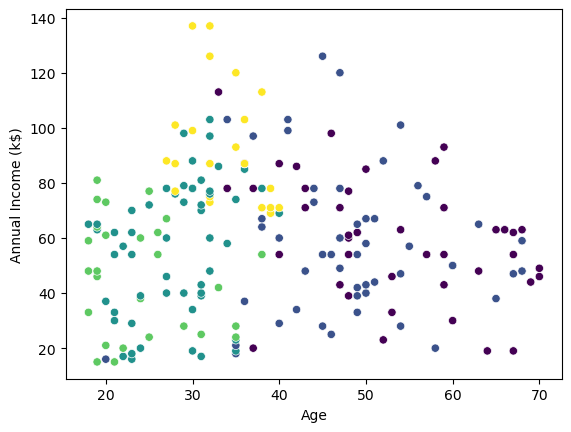

In [42]:
sns.scatterplot(data=X, x='Age', y='Annual Income (k$)', c= clusters)
plt.show()

In [43]:
px.scatter_3d(
    X,
    x='Age',
    y='Annual Income (k$)',
    z='Spending Score (1-100)',
    color = clusters
)

# Pair plot
    -option if dont want to perform PCA

In [44]:
pair_plot  = X

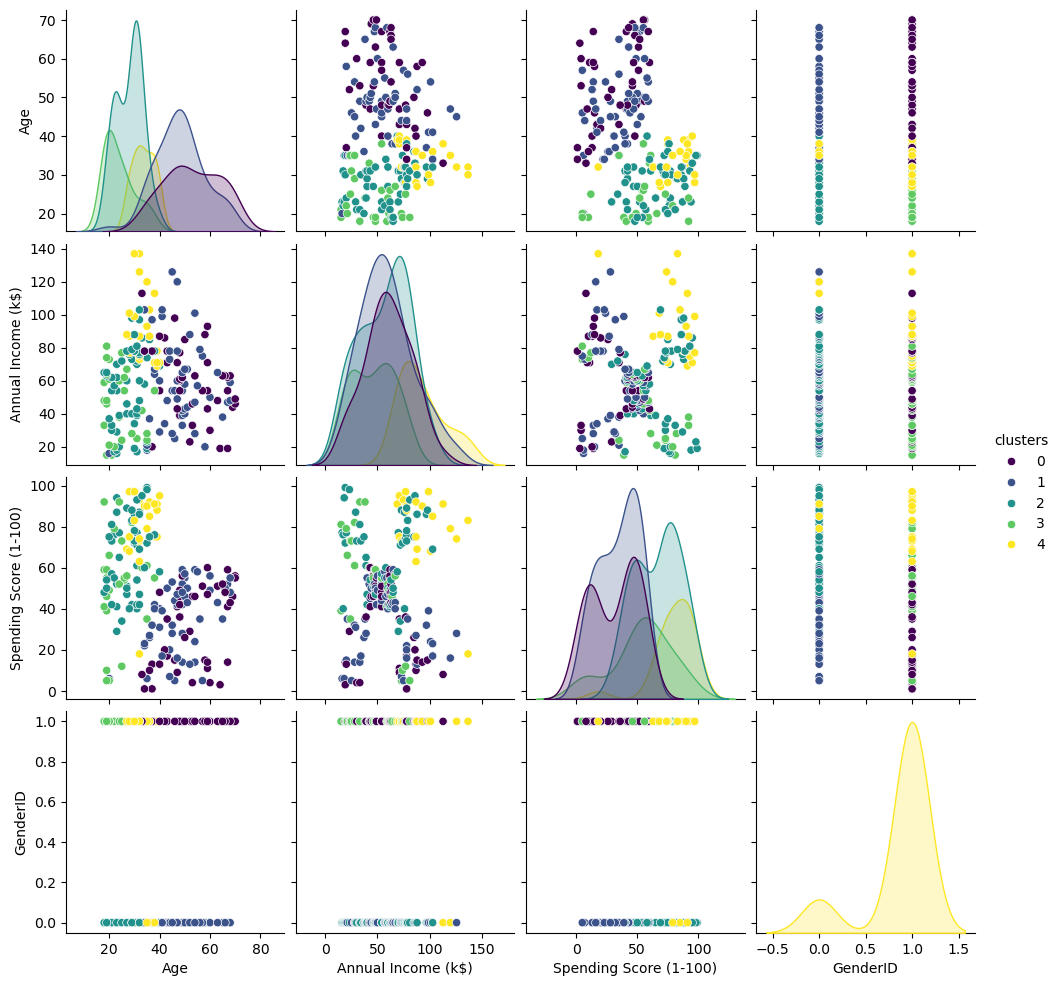

In [45]:
sns.pairplot(
    pair_plot,
    hue= 'clusters',
    palette='viridis'
)
plt.show()

## PCA (Principle Component Analysis)

-used only for visualization no analysis

In [46]:
from sklearn.decomposition import PCA

In [47]:
pca = PCA(n_components=len(features))

In [48]:
# Calculate co-variance of each row
pca_scale = pca.fit_transform(X_scale)
pca_scale

array([[-4.06382715e-01, -5.20713635e-01,  2.07252663e+00,
        -1.33552903e+00],
       [-1.42767287e+00, -3.67310199e-01,  2.27764369e+00,
        -8.23287388e-02],
       [ 5.07605706e-02, -1.89406774e+00,  3.67375232e-01,
        -2.17438112e+00],
       [-1.69451310e+00, -1.63190805e+00,  7.17466691e-01,
        -7.52284957e-02],
       [-3.13108383e-01, -1.81048272e+00,  4.26459924e-01,
        -6.83070448e-01],
       [-1.71744627e+00, -1.59926418e+00,  6.96379423e-01,
        -1.53191637e-01],
       [ 7.90821124e-01, -1.94727112e+00,  1.86491593e-01,
        -1.41185800e+00],
       [-2.14832159e+00, -1.50537369e+00,  7.58463596e-01,
         3.91407991e-01],
       [ 2.77428623e+00, -8.82987672e-01,  1.38814112e+00,
        -3.55576076e-02],
       [-1.21629477e+00, -1.61640464e+00,  5.55769702e-01,
         1.44050713e-01],
       [ 2.62905084e+00, -8.61237043e-01,  1.42011358e+00,
         4.18453647e-01],
       [-1.68947038e+00, -1.54542784e+00,  6.55007647e-01,
      

In [49]:
# Finding important data for axis called loadings
loadings = pd.DataFrame(
    pca.components_,
    index=features,
    columns=[f'PC(i+1)' for i in range(len(features))]
)
loadings
# only watch pc1 and 2 
# pc 3 and 4 ma outliers matra hunxa
# in ml ignores - or negative sign

,PC(i+1),PC(i+1),PC(i+1),PC(i+1)
Age,0.687900,-0.006082,-0.686920,0.234302
Annual Income (k$),-0.103690,0.765252,0.103211,0.626886
Spending Score (1-100),-0.122384,-0.643667,0.136573,0.743009
GenderID,0.707859,0.006721,0.706283,-0.007405


In [50]:
'''
PC1-> value high -> features -> X-axis
PC2-> value high -> features -> Y-axis

here, -0.7 considered greater than 0.6

X-> Age, Gender
Y-> Annual Income, Spending Score
'''

'\nPC1-> value high -> features -> X-axis\nPC2-> value high -> features -> Y-axis\n\nhere, -0.7 considered greater than 0.6\n\nX-> Age, Gender\nY-> Annual Income, Spending Score\n'

## Visualization PCA

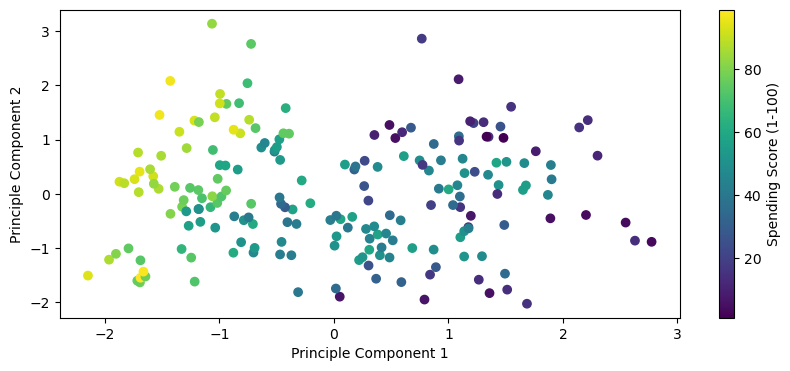

In [59]:
plt.figure(figsize=(10,4))
# color = 'Annual Income (k$)'
color = 'Spending Score (1-100)'
scatter= plt.scatter(pca_scale[:,0], pca_scale[:,1], c = df[color])
plt.colorbar(scatter, label= color)
plt.xlabel('Principle Component 1')
plt.ylabel('Principle Component 2')
plt.show()

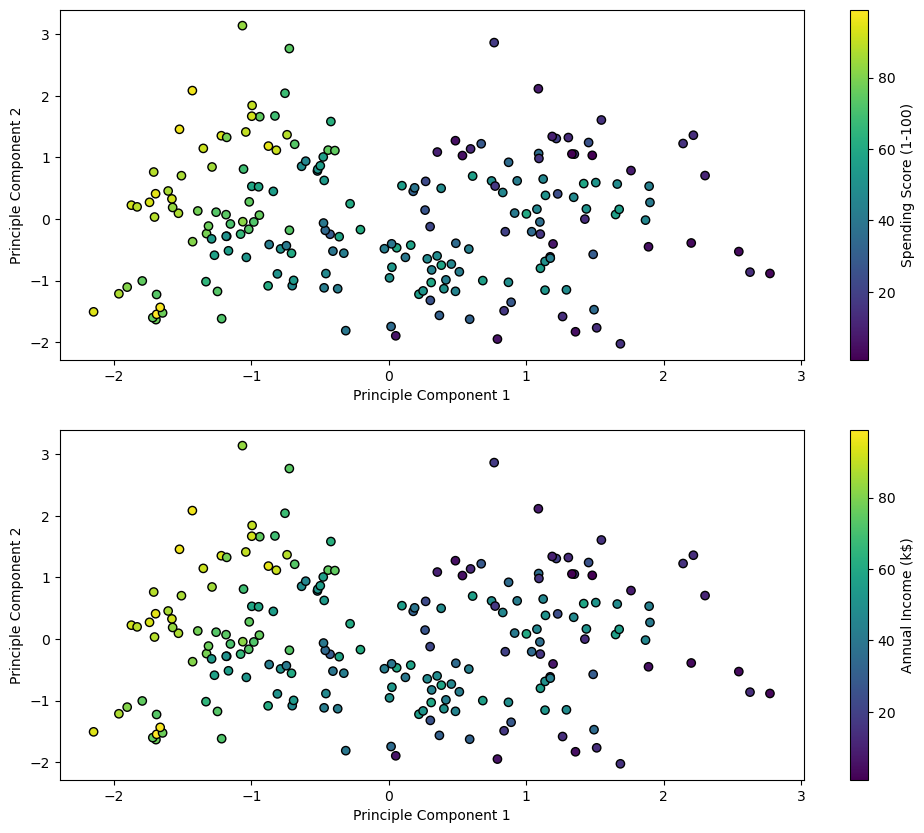

In [65]:
fig, axes = plt.subplots(2,1, figsize = (12, 10))

ax1 = axes[0]
color1 = 'Spending Score (1-100)'
scatter = ax1.scatter(pca_scale[:,0], pca_scale[:,1], c = df[color], edgecolor = '#000')
char = fig.colorbar(scatter, ax = ax1)
char.set_label(color1)
ax1.set_xlabel('Principle Component 1')
ax1.set_ylabel('Principle Component 2')

ax2 = axes[1]
color2 = 'Annual Income (k$)'
scatter = ax2.scatter(pca_scale[:,0], pca_scale[:,1], c = df[color], edgecolor = '#000')
char = fig.colorbar(scatter, ax = ax2)
char.set_label(color2)
ax2.set_xlabel('Principle Component 1')
ax2.set_ylabel('Principle Component 2')

plt.savefig('pca.png')
plt.show()